In [ ]:
from datetime import date

import geopandas as gpd
import matplotlib.pyplot as plt
import polars as pl

In [2]:
DIR = "/mnt/common-ssd/group-dirs/tkom-2026-project/pickwell/budapest/partitioned"

In [99]:
def prepare_for_duplicate_search(path: str, i: int) -> pl.DataFrame:
    df = pl.read_parquet(
        f"{path}/{i:02x}.parquet",
        columns=["timestamp", "device_id", "latitude", "longitude"],
    )
    return df.with_columns(
        pl.col("timestamp").dt.time().alias("time"),
        pl.col("timestamp").dt.date().alias("date"),
        pl.col("timestamp").dt.weekday().alias("dow"),
    )

In [96]:
records = []
for i in range(256):
    df = prepare_for_duplicate_search(f"{DIR}/with_speed", i)

    dupes = df.filter(
        df.select(["device_id", "time", "latitude", "longitude"]).is_duplicated()
    )
    dup_ratio = round(len(dupes) / len(df), 4)
    records.append((i, len(df), len(dupes), dup_ratio))

In [98]:
df.head()

timestamp,device_id,device_aid_type,latitude,longitude,distance_m,time_diff,time,date,dow
"datetime[μs, Europe/Budapest]",i64,str,f64,f64,f64,i32,time,date,i8
2025-06-16 00:02:20 CEST,1646109,"""AAID""",47.215942,18.553019,null,null,00:02:20,2025-06-16,1
2025-06-16 00:08:40 CEST,1646109,"""AAID""",47.215973,18.553019,0.007895,380,00:08:40,2025-06-16,1
2025-06-16 00:23:10 CEST,1646109,"""AAID""",47.221096,18.550361,0.694253,870,00:23:10,2025-06-16,1
2025-06-16 00:25:20 CEST,1646109,"""AAID""",47.215293,18.554689,5.561538,130,00:25:20,2025-06-16,1
2025-06-16 00:31:16 CEST,1646109,"""AAID""",47.216021,18.554184,0.252809,356,00:31:16,2025-06-16,1


In [102]:
dup_stat = pl.from_records(
    records,
    schema=["partition", "records", "duplicates", "duplicate_ratio"],
    orient="row",
)
dup_stat.write_csv("../output/budapest/duplicates.csv")

In [104]:
dup_stat["duplicates"].sum()

31835112

In [ ]:
round(dup_stat["duplicates"].sum() / dup_stat["records"].sum(), 5) * 100

1.113

In [ ]:
df = prepare_for_duplicate_search(f"{DIR}/with_speed", i)
dupes = df.filter(
    df.select(["device_id", "time", "latitude", "longitude"]).is_duplicated()
)
dupes = dupes.sort(["device_id", "date", "time", "latitude", "longitude"])

In [109]:
dup_ratio = round(len(dupes) / len(df), 4)

In [48]:
df.filter(
    (pl.col.device_id == 1)
    & (pl.col.date.is_in((date(2024, 10, 2), date(2024, 10, 9))))
)

timestamp,device_id,device_aid_type,latitude,longitude,distance_m,time_diff,speed_mps,time,date,dow
"datetime[μs, Europe/Budapest]",i64,str,f64,f64,i32,i32,f64,time,date,i8
2024-10-02 02:37:09 CEST,1,"""AAID""",47.47992,19.074155,null,null,null,02:37:09,2024-10-02,3
2024-10-02 03:17:49 CEST,1,"""AAID""",47.479995,19.074221,10,2440,0.004098,03:17:49,2024-10-02,3
2024-10-02 03:26:50 CEST,1,"""AAID""",47.476752,19.075154,367,541,0.678373,03:26:50,2024-10-02,3
2024-10-02 03:27:50 CEST,1,"""AAID""",47.47999,19.07423,367,60,6.116667,03:27:50,2024-10-02,3
2024-10-02 04:06:48 CEST,1,"""AAID""",47.476752,19.075154,367,2338,0.156972,04:06:48,2024-10-02,3
…,…,…,…,…,…,…,…,…,…,…
2024-10-09 17:26:36 CEST,1,"""AAID""",47.479703,19.074062,11,5565,0.001977,17:26:36,2024-10-09,3
2024-10-09 18:07:36 CEST,1,"""AAID""",47.479663,19.074022,5,2460,0.002033,18:07:36,2024-10-09,3
2024-10-09 18:54:47 CEST,1,"""AAID""",47.498402,19.0404,3275,2831,1.156835,18:54:47,2024-10-09,3


In [63]:
a = dupes.filter(
    (pl.col.device_id == 1) & (pl.col.date == date(2024, 10, 2))
).to_pandas()
a = gpd.GeoDataFrame(a, geometry=gpd.points_from_xy(a["longitude"], a["latitude"]))

In [ ]:
b = dupes.filter(
    (pl.col.device_id == 1) & (pl.col.date == date(2024, 10, 9))
).to_pandas()
b = gpd.GeoDataFrame(b, geometry=gpd.points_from_xy(b["longitude"], b["latitude"]))

In [ ]:
minx = min(a["longitude"].min(), b["longitude"].min()) * 0.9995
maxx = max(a["longitude"].max(), b["longitude"].max()) * 1.0005
miny = min(a["latitude"].min(), b["latitude"].min()) * 0.9995
maxy = max(a["latitude"].max(), b["latitude"].max()) * 1.0005

In [72]:
import contextily as cx

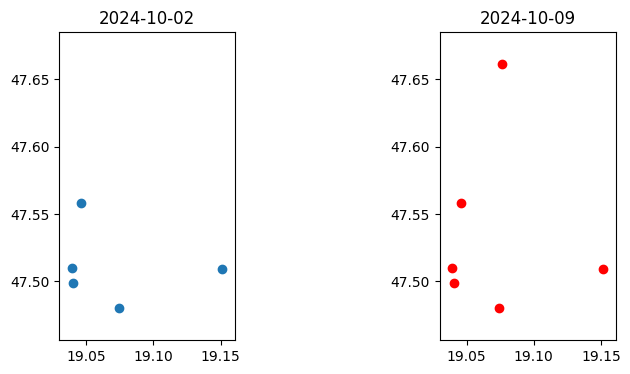

In [84]:
fig, axs = plt.subplots(ncols=2, figsize=(9, 4))
a.plot(ax=axs[0])
b.plot(ax=axs[1], color="red")
for ax, d in zip(axs, [date(2024, 10, 2), date(2024, 10, 9)]):
    ax.set_xlim([minx, maxx])
    ax.set_ylim([miny, maxy])
    # cx.add_basemap(ax, crs=a.crs, source=cx.providers.CartoDB.PositronNoLabels, zoom=14)
    ax.set_title(d)

In [86]:
a

,timestamp,device_id,device_aid_type,latitude,longitude,distance_m,time_diff,speed_mps,time,date,dow,geometry
0,2024-10-02 05:30:54+02:00,1,AAID,47.479812,19.074090,350,2643,0.132425,05:30:54,2024-10-02,3,POINT (19.07409 47.47981)
1,2024-10-02 06:44:26+02:00,1,AAID,47.509760,19.039530,2679,7,382.714286,06:44:26,2024-10-02,3,POINT (19.03953 47.50976)
2,2024-10-02 09:17:56+02:00,1,AAID,47.509079,19.151371,0,1200,0.000000,09:17:56,2024-10-02,3,POINT (19.15137 47.50908)
3,2024-10-02 15:33:40+02:00,1,AAID,47.557891,19.046058,6464,584,11.068493,15:33:40,2024-10-02,3,POINT (19.04606 47.55789)
4,2024-10-02 18:54:47+02:00,1,AAID,47.498402,19.040400,3331,1585,2.101577,18:54:47,2024-10-02,3,POINT (19.0404 47.4984)


In [85]:
b

,timestamp,device_id,device_aid_type,latitude,longitude,distance_m,time_diff,speed_mps,time,date,dow,geometry
0,2024-10-09 05:30:54+02:00,1,AAID,47.479812,19.074090,343,1938,0.176987,05:30:54,2024-10-09,3,POINT (19.07409 47.47981)
1,2024-10-09 06:44:26+02:00,1,AAID,47.509760,19.039530,866,84,10.309524,06:44:26,2024-10-09,3,POINT (19.03953 47.50976)
2,2024-10-09 09:17:56+02:00,1,AAID,47.509079,19.151371,0,307,0.000000,09:17:56,2024-10-09,3,POINT (19.15137 47.50908)
3,2024-10-09 09:32:40+02:00,1,AAID,47.661260,19.076190,17836,884,20.176471,09:32:40,2024-10-09,3,POINT (19.07619 47.66126)
4,2024-10-09 15:33:40+02:00,1,AAID,47.557891,19.046058,3626,449,8.075724,15:33:40,2024-10-09,3,POINT (19.04606 47.55789)
5,2024-10-09 18:54:47+02:00,1,AAID,47.498402,19.040400,3275,2831,1.156835,18:54:47,2024-10-09,3,POINT (19.0404 47.4984)


In [87]:
from datetime import time

In [ ]:
dupes.filter(pl.col.device_id == 1, pl.col.time == time(9, 32, 40))

timestamp,device_id,device_aid_type,latitude,longitude,distance_m,time_diff,speed_mps,time,date,dow
"datetime[μs, Europe/Budapest]",i64,str,f64,f64,i32,i32,f64,time,date,i8
2024-10-09 09:32:40 CEST,1,"""AAID""",47.66126,19.07619,17836,884,20.176471,09:32:40,2024-10-09,3
2024-10-16 09:32:40 CEST,1,"""AAID""",47.66126,19.07619,4,2495,0.001603,09:32:40,2024-10-16,3
